# 070 CASE 120 — Water quality: Stigfjorden

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** Where is the spring bloom visible in the water off Tjörn and Marstrand?

**Area:** Marstrand, southern Tjörn and Stigfjorden (Bohuslän), 8 April 2026.

**Partners:** RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2026.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes two to three minutes.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    user, password = input("DES username: "), getpass("DES password: ")
    if not (user and password):
        raise ValueError("enter both a DES username and a password")
    des.authenticate_basic(user, password)
    del password
else:
    des.authenticate_oidc(provider_id="egi")

# Every IMINT Engine fetch below uses this login and no other credentials on the machine
# (the pinned engine has no public parameter for a connection yet).
imint.fetch._connect = lambda token=None, token_path=None: des
clear_output()  # keep the typed username and the login link out of a saved notebook
print("Logged in to Digital Earth Sweden.")


## 1. Method

```
AOI + date → fetch_des_data → WaterQualityAnalyzer (water mask from SCL, NDCI and MCI) → maps over water
```

Two band indices respond to phytoplankton. NDCI, the normalised difference chlorophyll index
(B05 − B04) / (B05 + B04), follows chlorophyll-a in coastal water. MCI, the maximum chlorophyll
index, measures how far B05 rises above a line between B04 and B06, and picks out dense blooms.
`WaterQualityAnalyzer` can also run two calibrated models that give chlorophyll in mg/m³ (MDN and
C2RCC), but they need extra software, so this notebook uses the two indices.

## 2. Area and data

The map is interactive when the notebook runs in Jupyter; GitHub's viewer shows only a placeholder for it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene


def true_colour(scene, top=0.25):
    """True colour with a fixed stretch, so different dates are comparable."""
    return np.clip(np.dstack([scene.bands[b] for b in ("B04", "B03", "B02")]) / top, 0, 1)

AOI = {"west": 11.3187, "south": 58.0416, "east": 11.7403, "north": 58.1424}  # Marstrand, Tjörn, Stigfjorden
DATE = "2026-04-08"

scene = load_scene(DATE, AOI, max_cloud=0.5)

    Cloud fraction: 0.0%


2026-04-08: 11 bands, 1250 x 2543 px at 10 m, cloud and shadow 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#1971c2", weight=2, fill=False, popup="Stigfjorden",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Water quality indices

In [4]:
from imint.analyzers.water_quality import WaterQualityAnalyzer

config = {"methods": {"mdn": {"enabled": False}, "c2rcc": {"enabled": False}}}  # indices only
wq = WaterQualityAnalyzer(config).run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                      output_dir="outputs/120", scl=scene.scl, geo=scene.geo)
print(wq.summary())
water = np.asarray(wq.outputs["water_mask"]) > 0
print(f"water pixels analysed: {water.sum():,} ({water.mean():.0%} of the area)")
indices = {name: np.where(water, np.asarray(wq.outputs[name], dtype=float), np.nan) for name in ("ndci", "mci")}
for name, arr in indices.items():
    print(f"{name.upper():4s} median {np.nanmedian(arr):+.4f}, "
          f"5th–95th pct {np.nanpercentile(arr, 5):+.4f} … {np.nanpercentile(arr, 95):+.4f}")

[water_quality] OK — outputs: ndci, mci, water_mask
water pixels analysed: 1,258,566 (40% of the area)
NDCI median -0.1939, 5th–95th pct -0.2665 … +0.0567
MCI  median -0.0004, 5th–95th pct -0.0017 … +0.0085


## 4. Results

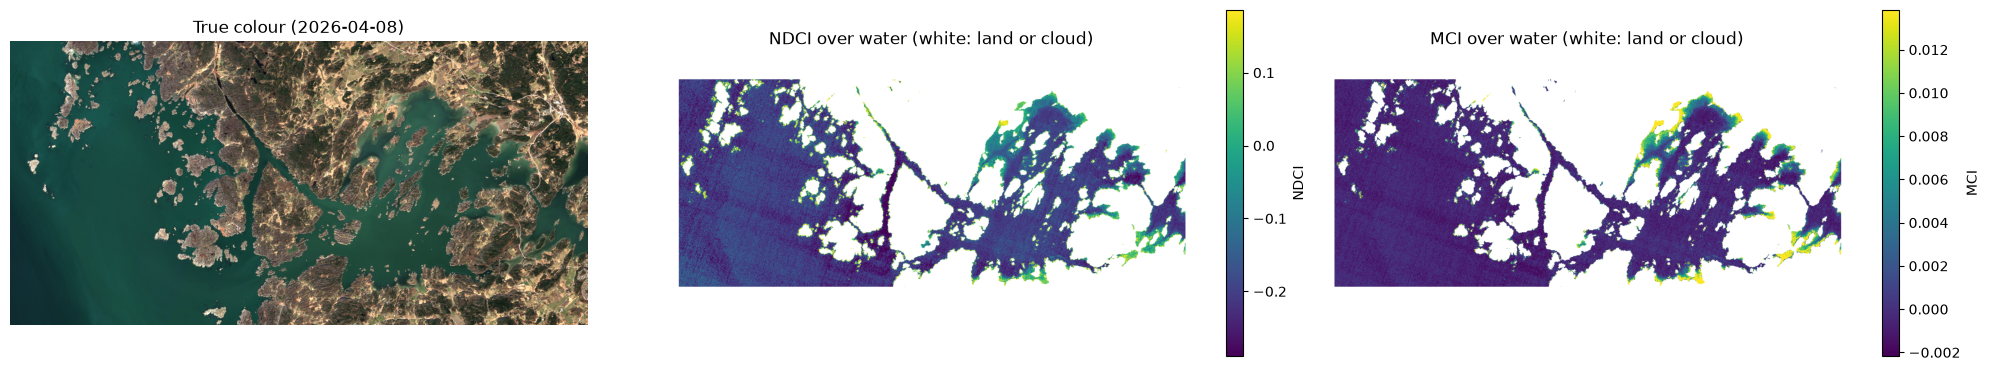

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].imshow(true_colour(scene, top=0.15)); axes[0].set_title(f"True colour ({DATE})")
for ax, name, label in [(axes[1], "ndci", "NDCI"), (axes[2], "mci", "MCI")]:
    arr = indices[name]
    lo, hi = np.nanpercentile(arr, [2, 98])
    im = ax.imshow(arr, cmap="viridis", vmin=lo, vmax=hi)
    ax.set_title(f"{label} over water (white: land or cloud)")
    fig.colorbar(im, ax=ax, fraction=0.03, label=label)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

Higher NDCI and MCI mark more phytoplankton. Both are indices, not concentrations: river plumes,
suspended sediment and a visible sea floor in shallow water also raise them, so patterns near the
shore and in the inner fjords need care. Comparing the same area over several spring dates, or
running the calibrated MDN or C2RCC models, turns the patterns into chlorophyll estimates.

**Links:** [`imint/analyzers/water_quality`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/water_quality)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).